# Task 7 — Deep Learning Model Development
### UniMatch AI — 10-Task Computational Intelligence Pipeline

**Input:** Feature Matrix from Task 5 (`feature_matrix_university.csv`, `feature_matrix_graduate.csv`, `selected_features.json`). Optional: Task 6 `evaluation_report_*.csv` for the ML vs DL comparison.

**Steps:** Neural network design → Hyperparameter selection → Model training → Validation → Overfitting prevention → Performance evaluation → Model saving

**Deliverables:** DNN Model (`.h5`), Training History, Accuracy / Loss Curves, Evaluation Report, Hyperparameter Report

> **Same data, same split as Task 6** so the DNN can be compared fairly with the ML models:
> - **University Master** — target `admit` (0/1); uses the `split` column saved by Task 5.
> - **Graduate Admission** — `chance_of_admit` binarised at **0.7** (same threshold as Task 6); same `train_test_split(test_size=0.2, random_state=42, stratify=y)` call as Task 6.
>
> **Running in Colab:** run Tasks 4 → 5 → 6 → 7 in the same Colab session (files are then already in place), or put the Task 5/6 output folders in Google Drive (see Section 1). Large CSVs uploaded through the browser can get cut off — the loader below checks for that.

## 0. Setup

In [ ]:
import os, json, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42
keras.utils.set_random_seed(RANDOM_STATE)      # seeds Python, NumPy and TensorFlow
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 100)

out_dir = './task7_outputs'
os.makedirs(out_dir, exist_ok=True)
print('TensorFlow', tf.__version__)

TensorFlow 2.21.0


## 1. Load Task 5 outputs

`find_file` looks in the current folder, the Task 5/6 output folders and a Drive folder. Change `DRIVE_DIR` if you keep the project somewhere else in Drive.

In [ ]:
DRIVE_DIR = '/content/drive/MyDrive/UniMatch'
SEARCH_DIRS = ['.', './task5_outputs', './task6_outputs', '/content', DRIVE_DIR,
               f'{DRIVE_DIR}/task5_outputs', f'{DRIVE_DIR}/task6_outputs']

def find_file(name):
    for d in SEARCH_DIRS:
        p = os.path.join(d, name)
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"'{name}' not found in {SEARCH_DIRS}. Run Task 5/6 first, "
                            "or upload the file / put it in DRIVE_DIR.")

def check_complete(df, name, target):
    # A CSV cut off during upload ends with a partial last row -> missing target value.
    n_bad = int(df[target].isna().sum())
    if n_bad:
        raise ValueError(f"{name}: {n_bad} row(s) have no '{target}'. The file looks truncated - "
                         "re-create it in this session or load it from Drive instead of uploading.")

uni_df  = pd.read_csv(find_file('feature_matrix_university.csv'))
grad_df = pd.read_csv(find_file('feature_matrix_graduate.csv'))
with open(find_file('selected_features.json')) as f:
    selected = json.load(f)

check_complete(uni_df, 'feature_matrix_university.csv', 'admit')
check_complete(grad_df, 'feature_matrix_graduate.csv', 'chance_of_admit')

print('University feature matrix:', uni_df.shape, '| split counts:', uni_df['split'].value_counts().to_dict())
print('Graduate feature matrix:  ', grad_df.shape)
print('Selected features:', {k: len(v) for k, v in selected.items()})

University feature matrix: (53527, 30) | split counts: {'train': 42821, 'test': 10706}
Graduate feature matrix:   (500, 9)
Selected features: {'university_dataset': 15, 'graduate_dataset': 3}


## 2. Prepare features, targets and splits

- Same selected features as Task 6.
- **Train / validation / test:** the test set is the Task 6 test set. A further 15% of the training rows is held out as a **validation set** for early stopping and hyperparameter selection — the test set is used only once, at the end.
- Features are standardised with a scaler **fit on the training rows only** (neural networks need scaled inputs).

In [ ]:
THRESHOLD = 0.7   # Graduate dataset: chance_of_admit >= 0.7 -> admitted (same as Task 6)

def make_splits(X, y, train_mask=None):
    """Return scaled train / val / test arrays plus the fitted scaler."""
    if train_mask is not None:                       # University: split from Task 5
        X_tr_full, X_te = X[train_mask], X[~train_mask]
        y_tr_full, y_te = y[train_mask], y[~train_mask]
    else:                                            # Graduate: identical call to Task 6
        X_tr_full, X_te, y_tr_full, y_te = train_test_split(
            X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
    X_tr, X_val, y_tr, y_val = train_test_split(
        X_tr_full, y_tr_full, test_size=0.15, random_state=RANDOM_STATE, stratify=y_tr_full)
    scaler = StandardScaler().fit(X_tr)
    t = lambda a: scaler.transform(a).astype('float32')
    return dict(X_tr=t(X_tr), X_val=t(X_val), X_te=t(X_te),
                y_tr=y_tr.values, y_val=y_val.values, y_te=y_te.values,
                X_te_raw=X_te, scaler=scaler, features=list(X.columns))

feat_a = [c for c in selected['university_dataset'] if c in uni_df.columns]
feat_b = [c for c in selected['graduate_dataset'] if c in grad_df.columns]

data = {
    'university': make_splits(uni_df[feat_a], uni_df['admit'].astype(int), train_mask=(uni_df['split'] == 'train').values),
    'graduate':   make_splits(grad_df[feat_b], (grad_df['chance_of_admit'] >= THRESHOLD).astype(int)),
}
for name, d in data.items():
    print(f"{name:10s} features={len(d['features'])}  train={len(d['y_tr'])}  val={len(d['y_val'])}  test={len(d['y_te'])}  "
          f"positive rate (train)={d['y_tr'].mean():.3f}")

university features=15  train=36397  val=6424  test=10706  positive rate (train)=0.522
graduate   features=3  train=340  val=60  test=100  positive rate (train)=0.600


## 3. Neural network design

A feed-forward network (multi-layer perceptron) for tabular data:

| Part | Choice | Why |
|---|---|---|
| Hidden layers | Dense + ReLU | standard, fast to train on tabular features |
| Regularisation | Dropout + L2 weight decay | **overfitting prevention** |
| Output | 1 unit, sigmoid | probability of admission |
| Loss / optimiser | binary cross-entropy, Adam | standard for binary classification |
| Class imbalance | `class_weight='balanced'` | same idea as Task 6 |
| Training control | EarlyStopping on validation AUC (restores best weights) + ReduceLROnPlateau | **overfitting prevention** |

In [ ]:
def build_model(n_features, hidden=(64, 32), dropout=0.3, l2=1e-4, lr=1e-3):
    model = keras.Sequential([layers.Input(shape=(n_features,))])
    for units in hidden:
        model.add(layers.Dense(units, activation='relu', kernel_regularizer=regularizers.l2(l2)))
        model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation='sigmoid'))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss='binary_crossentropy',
                  metrics=['accuracy', keras.metrics.AUC(name='auc')])
    return model

build_model(len(feat_a)).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,137 (12.25 KB)

 Trainable params: 3,137 (12.25 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Hyperparameter selection, training and validation

A small grid of architectures / learning rates is trained for each dataset. Every run uses early stopping on the **validation** AUC; the configuration with the best validation AUC is kept. The test set is not touched here.

In [ ]:
CONFIGS = [
    {'hidden': (32, 16),      'dropout': 0.2, 'l2': 1e-4, 'lr': 1e-3},
    {'hidden': (64, 32),      'dropout': 0.3, 'l2': 1e-4, 'lr': 1e-3},
    {'hidden': (128, 64, 32), 'dropout': 0.3, 'l2': 1e-4, 'lr': 1e-3},
    {'hidden': (64, 32),      'dropout': 0.3, 'l2': 1e-3, 'lr': 3e-4},
]
BATCH = {'university': 256, 'graduate': 32}
MAX_EPOCHS = 300

def train_one(d, cfg, batch_size):
    keras.utils.set_random_seed(RANDOM_STATE)
    model = build_model(d['X_tr'].shape[1], **cfg)
    cw = compute_class_weight('balanced', classes=np.array([0, 1]), y=d['y_tr'])
    callbacks = [
        keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=20, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=8, min_lr=1e-5),
    ]
    hist = model.fit(d['X_tr'], d['y_tr'], validation_data=(d['X_val'], d['y_val']),
                     epochs=MAX_EPOCHS, batch_size=batch_size, class_weight={0: cw[0], 1: cw[1]},
                     callbacks=callbacks, verbose=0)
    h = pd.DataFrame(hist.history)
    best_epoch = int(h['val_auc'].idxmax())
    return model, h, best_epoch

results, best = {}, {}
for name, d in data.items():
    rows = []
    for i, cfg in enumerate(CONFIGS):
        model, h, ep = train_one(d, cfg, BATCH[name])
        rows.append({'config': i, 'hidden': str(cfg['hidden']), 'dropout': cfg['dropout'], 'l2': cfg['l2'],
                     'learning_rate': cfg['lr'], 'epochs_run': len(h), 'best_epoch': ep + 1,
                     'train_auc': h.loc[ep, 'auc'], 'val_auc': h.loc[ep, 'val_auc'],
                     'train_loss': h.loc[ep, 'loss'], 'val_loss': h.loc[ep, 'val_loss']})
        if name not in best or h.loc[ep, 'val_auc'] > best[name]['val_auc']:
            best[name] = {'model': model, 'history': h, 'cfg': cfg, 'config': i, 'val_auc': h.loc[ep, 'val_auc']}
        print(f"{name:10s} config {i} {cfg} -> val AUC {h.loc[ep, 'val_auc']:.4f} (best epoch {ep + 1}/{len(h)})")
    results[name] = pd.DataFrame(rows).sort_values('val_auc', ascending=False).reset_index(drop=True)
    print(f"--> best for {name}: config {best[name]['config']} {best[name]['cfg']}\n")

university config 0 {'hidden': (32, 16), 'dropout': 0.2, 'l2': 0.0001, 'lr': 0.001} -> val AUC 0.7231 (best epoch 147/167)
university config 1 {'hidden': (64, 32), 'dropout': 0.3, 'l2': 0.0001, 'lr': 0.001} -> val AUC 0.7355 (best epoch 159/179)
university config 2 {'hidden': (128, 64, 32), 'dropout': 0.3, 'l2': 0.0001, 'lr': 0.001} -> val AUC 0.7534 (best epoch 115/135)
university config 3 {'hidden': (64, 32), 'dropout': 0.3, 'l2': 0.001, 'lr': 0.0003} -> val AUC 0.7143 (best epoch 171/191)
--> best for university: config 2 {'hidden': (128, 64, 32), 'dropout': 0.3, 'l2': 0.0001, 'lr': 0.001}

graduate   config 0 {'hidden': (32, 16), 'dropout': 0.2, 'l2': 0.0001, 'lr': 0.001} -> val AUC 0.9282 (best epoch 9/29)
graduate   config 1 {'hidden': (64, 32), 'dropout': 0.3, 'l2': 0.0001, 'lr': 0.001} -> val AUC 0.9352 (best epoch 28/48)
graduate   config 2 {'hidden': (128, 64, 32), 'dropout': 0.3, 'l2': 0.0001, 'lr': 0.001} -> val AUC 0.9369 (best epoch 55/75)
graduate   config 3 {'hidden': (

In [ ]:
hyperparameter_report = pd.concat([r.assign(dataset=n) for n, r in results.items()], ignore_index=True)
hyperparameter_report = hyperparameter_report[['dataset'] + [c for c in hyperparameter_report.columns if c != 'dataset']]
hyperparameter_report.to_csv(f'{out_dir}/hyperparameter_report.csv', index=False)
hyperparameter_report.round(4)

,dataset,config,hidden,dropout,l2,learning_rate,epochs_run,best_epoch,train_auc,val_auc,train_loss,val_loss
0,university,2,"(128, 64, 32)",0.3,0.0001,0.0010,135,115,0.7658,0.7534,0.5871,0.5981
1,university,1,"(64, 32)",0.3,0.0001,0.0010,179,159,0.7332,0.7355,0.6098,0.6086
2,university,0,"(32, 16)",0.2,0.0001,0.0010,167,147,0.7140,0.7231,0.6218,0.6170
3,university,3,"(64, 32)",0.3,0.0010,0.0003,191,171,0.7109,0.7143,0.6280,0.6265
4,graduate,2,"(128, 64, 32)",0.3,0.0001,0.0010,75,55,0.9311,0.9369,0.3483,0.3177
5,graduate,1,"(64, 32)",0.3,0.0001,0.0010,48,28,0.9285,0.9352,0.3433,0.3378
6,graduate,3,"(64, 32)",0.3,0.0010,0.0003,104,84,0.9348,0.9352,0.3557,0.3657
7,graduate,0,"(32, 16)",0.2,0.0001,0.0010,29,9,0.9115,0.9282,0.4189,0.3978


## 5. Training history — accuracy / loss curves

The dashed line marks the epoch whose weights were kept (best validation AUC). Train and validation curves staying close together means the regularisation is keeping overfitting under control.

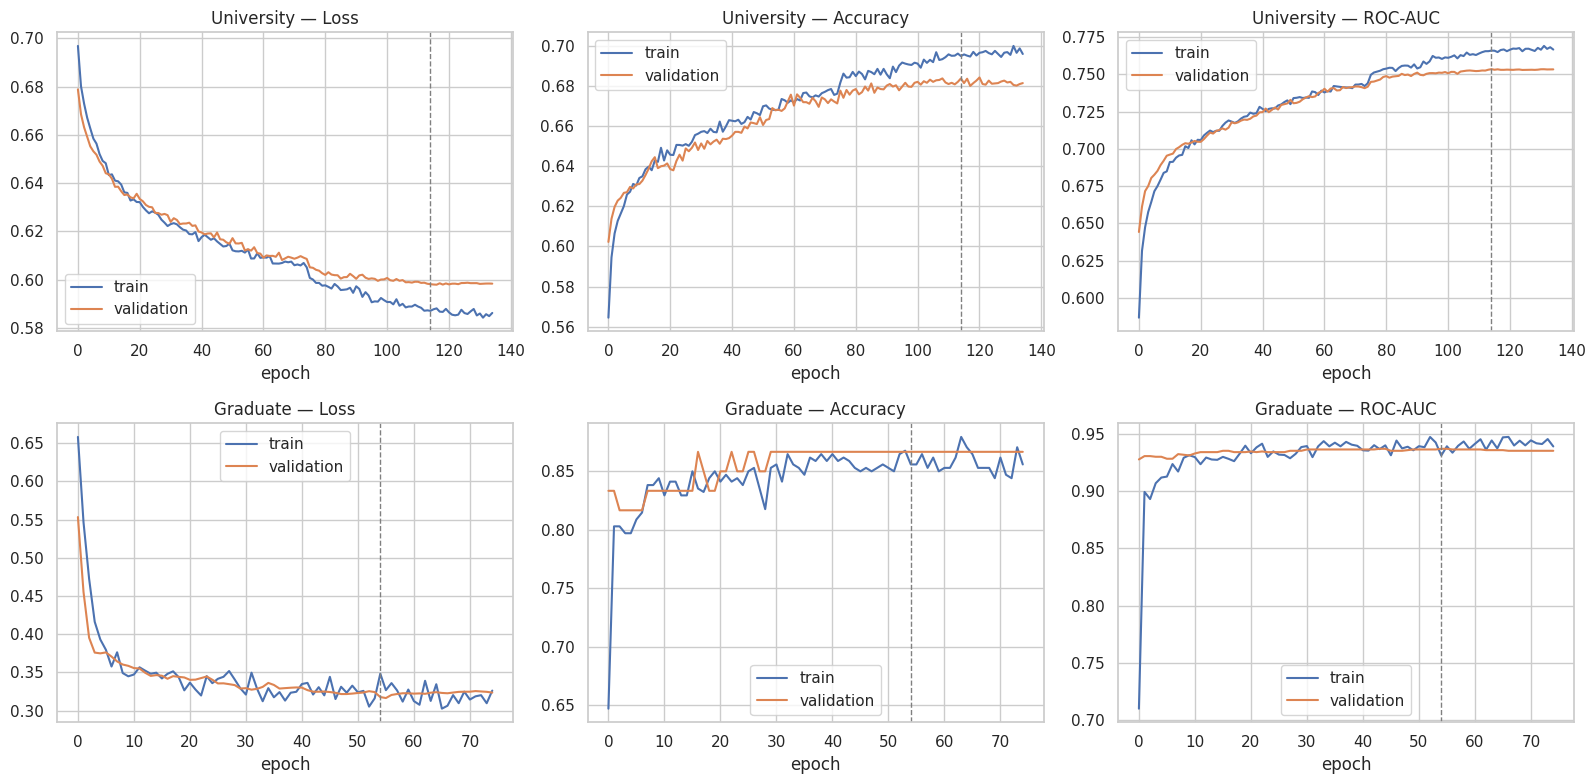

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for row, name in enumerate(data):
    h, ep = best[name]['history'], int(best[name]['history']['val_auc'].idxmax())
    for col, (m, label) in enumerate([('loss', 'Loss'), ('accuracy', 'Accuracy'), ('auc', 'ROC-AUC')]):
        ax = axes[row, col]
        ax.plot(h[m], label='train'); ax.plot(h[f'val_{m}'], label='validation')
        ax.axvline(ep, ls='--', color='grey', lw=1)
        ax.set_title(f'{name.title()} — {label}'); ax.set_xlabel('epoch'); ax.legend()
    best[name]['history'].to_csv(f'{out_dir}/training_history_{name}.csv', index_label='epoch')
plt.tight_layout()
plt.savefig(f'{out_dir}/accuracy_loss_curves.png', dpi=150)
plt.show()

## 6. Performance evaluation on the held-out test set

Same metrics as Task 6 (including minority-class metrics), plus a train / validation / test AUC comparison as an **overfitting check**.

In [ ]:
def metrics(y, p, thr=0.5):
    yhat = (p >= thr).astype(int)
    minority = int(pd.Series(y).value_counts().idxmin())
    return {'accuracy': accuracy_score(y, yhat), 'precision': precision_score(y, yhat, zero_division=0),
            'recall': recall_score(y, yhat, zero_division=0), 'f1': f1_score(y, yhat, zero_division=0),
            f'precision_minority(class {minority})': precision_score(y, yhat, pos_label=minority, zero_division=0),
            f'recall_minority(class {minority})': recall_score(y, yhat, pos_label=minority, zero_division=0),
            f'f1_minority(class {minority})': f1_score(y, yhat, pos_label=minority, zero_division=0),
            'roc_auc': roc_auc_score(y, p)}

eval_rows, overfit_rows, probs = [], [], {}
for name, d in data.items():
    m = best[name]['model']
    p = {s: m.predict(d[f'X_{s}'], verbose=0).ravel() for s in ['tr', 'val', 'te']}
    probs[name] = p['te']
    eval_rows.append({'dataset': name, 'model': 'DNN', **metrics(d['y_te'], p['te'])})
    overfit_rows.append({'dataset': name, 'train_auc': roc_auc_score(d['y_tr'], p['tr']),
                         'val_auc': roc_auc_score(d['y_val'], p['val']), 'test_auc': roc_auc_score(d['y_te'], p['te'])})

evaluation_report = pd.DataFrame(eval_rows)
overfit = pd.DataFrame(overfit_rows)
overfit['train_test_gap'] = overfit['train_auc'] - overfit['test_auc']
display(evaluation_report.round(4))
display(overfit.round(4))

,dataset,model,accuracy,precision,recall,f1,precision_minority(class 0),recall_minority(class 0),f1_minority(class 0),roc_auc
0,university,DNN,0.6824,0.7161,0.6482,0.6805,0.6523,0.7198,0.6844,0.7534
1,graduate,DNN,0.8700,0.8983,0.8833,0.8908,0.8293,0.8500,0.8395,0.9504


,dataset,train_auc,val_auc,test_auc,train_test_gap
0,university,0.7991,0.7533,0.7534,0.0457
1,graduate,0.9461,0.9375,0.9504,-0.0043


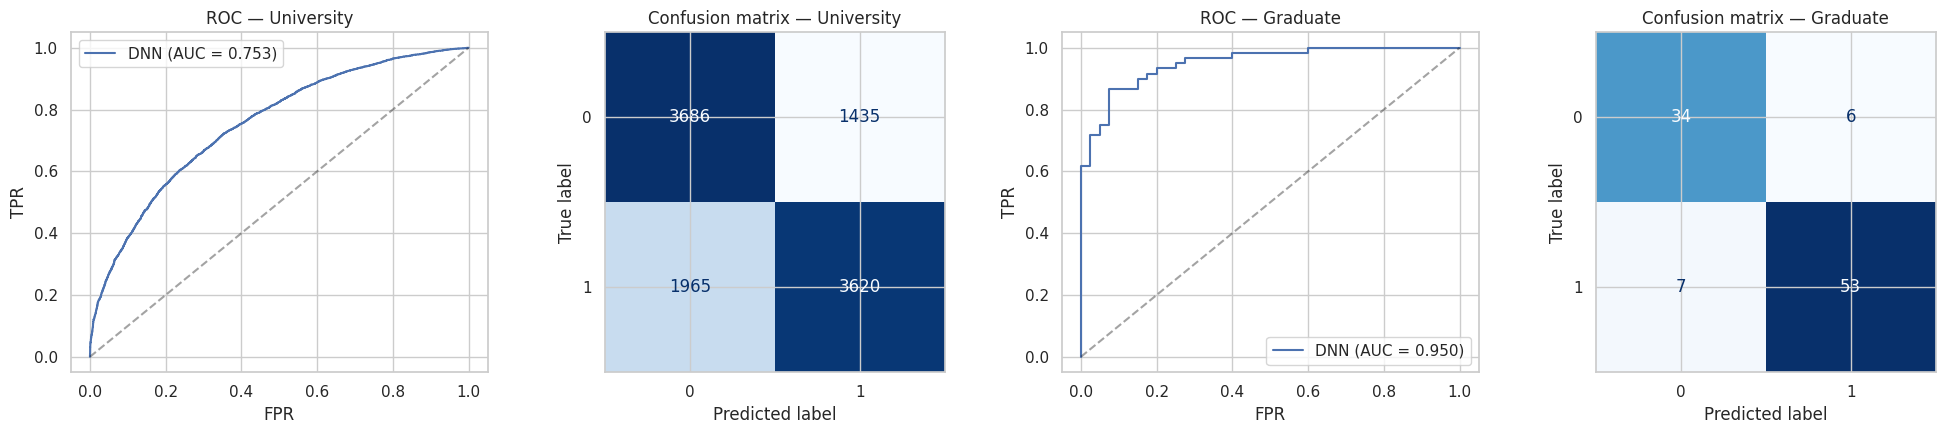

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for i, (name, d) in enumerate(data.items()):
    fpr, tpr, _ = roc_curve(d['y_te'], probs[name])
    axes[2 * i].plot(fpr, tpr, label=f"DNN (AUC = {roc_auc_score(d['y_te'], probs[name]):.3f})")
    axes[2 * i].plot([0, 1], [0, 1], 'k--', alpha=0.4)
    axes[2 * i].set_title(f'ROC — {name.title()}'); axes[2 * i].set_xlabel('FPR'); axes[2 * i].set_ylabel('TPR'); axes[2 * i].legend()
    ConfusionMatrixDisplay(confusion_matrix(d['y_te'], (probs[name] >= 0.5).astype(int))).plot(
        ax=axes[2 * i + 1], colorbar=False, cmap='Blues')
    axes[2 * i + 1].set_title(f'Confusion matrix — {name.title()}')
plt.tight_layout()
plt.savefig(f'{out_dir}/dnn_roc_confusion.png', dpi=150)
plt.show()

### 6.1 DNN vs best Task 6 ML model

Uses Task 6's `evaluation_report_*.csv` if it can be found; otherwise this cell is skipped.

In [ ]:
comparison = []
for name in data:
    try:
        ml = pd.read_csv(find_file(f'evaluation_report_{name}.csv')).sort_values('roc_auc', ascending=False).iloc[0]
        comparison.append({'dataset': name, 'model': f"{ml['model']} (Task 6 best)", 'accuracy': ml['accuracy'],
                           'f1': ml['f1'], 'roc_auc': ml['roc_auc']})
    except FileNotFoundError:
        print(f'Task 6 report for {name} not found - skipping comparison.')
    r = evaluation_report[evaluation_report['dataset'] == name].iloc[0]
    comparison.append({'dataset': name, 'model': 'DNN (Task 7)', 'accuracy': r['accuracy'], 'f1': r['f1'], 'roc_auc': r['roc_auc']})
comparison = pd.DataFrame(comparison)
comparison.round(4)

,dataset,model,accuracy,f1,roc_auc
0,university,XGBoost (Task 6 best),0.7289,0.7346,0.8005
1,university,DNN (Task 7),0.6824,0.6805,0.7534
2,graduate,Logistic Regression (Task 6 best),0.9000,0.9153,0.9479
3,graduate,DNN (Task 7),0.8700,0.8908,0.9504


## 7. Save the models and deliverables

In [ ]:
for name, d in data.items():
    m = best[name]['model']
    m.save(f'{out_dir}/dnn_{name}.h5')          # deliverable format (.h5)
    m.save(f'{out_dir}/dnn_{name}.keras')       # native Keras format (recommended for reloading)
    joblib.dump(d['scaler'], f'{out_dir}/dnn_scaler_{name}.pkl')

with open(f'{out_dir}/dnn_config.json', 'w') as f:
    json.dump({name: {'features': data[name]['features'], 'best_config': {k: list(v) if isinstance(v, tuple) else v
               for k, v in best[name]['cfg'].items()}, 'threshold_for_label': 0.5}
               for name in data} | {'graduate_target_threshold': THRESHOLD}, f, indent=2)

evaluation_report.to_csv(f'{out_dir}/evaluation_report_dnn.csv', index=False)
overfit.to_csv(f'{out_dir}/overfitting_check.csv', index=False)
comparison.to_csv(f'{out_dir}/dnn_vs_ml_comparison.csv', index=False)

report = f'''# Evaluation Report — Task 7 (Deep Learning)

## Best configurations (chosen on validation AUC)
{hyperparameter_report.groupby('dataset').head(1).to_markdown(index=False)}

## Test-set performance
{evaluation_report.to_markdown(index=False)}

## Overfitting check (ROC-AUC)
{overfit.to_markdown(index=False)}

## DNN vs best ML model (Task 6)
{comparison.to_markdown(index=False)}

## Notes
- Same features, targets and test sets as Task 6; 15% of the training rows used as a validation set.
- Overfitting prevention: dropout, L2 weight decay, early stopping on validation AUC (best weights restored), learning-rate reduction.
- Scaler fit on the training rows only; saved as `dnn_scaler_<dataset>.pkl` and must be applied before prediction.
'''
with open(f'{out_dir}/evaluation_report_dnn.md', 'w') as f:
    f.write(report)
print(report)

# Evaluation Report — Task 7 (Deep Learning)

## Best configurations (chosen on validation AUC)
| dataset    |   config | hidden        |   dropout |     l2 |   learning_rate |   epochs_run |   best_epoch |   train_auc |   val_auc |   train_loss |   val_loss |
|:-----------|---------:|:--------------|----------:|-------:|----------------:|-------------:|-------------:|------------:|----------:|-------------:|-----------:|
| university |        2 | (128, 64, 32) |       0.3 | 0.0001 |           0.001 |          135 |          115 |    0.765836 |  0.753384 |     0.587127 |   0.598148 |
| graduate   |        2 | (128, 64, 32) |       0.3 | 0.0001 |           0.001 |           75 |           55 |    0.93112  |  0.936921 |     0.348287 |   0.317701 |

## Test-set performance
| dataset    | model   |   accuracy |   precision |   recall |       f1 |   precision_minority(class 0) |   recall_minority(class 0) |   f1_minority(class 0) |   roc_auc |
|:-----------|:--------|-----------:|----------

In [ ]:
shutil.make_archive('task7_deliverables', 'zip', out_dir)
try:
    from google.colab import files
    files.download('task7_deliverables.zip')
except ModuleNotFoundError:
    print("Saved 'task7_deliverables.zip' in the current working directory.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Task 7 Deliverables Checklist

- [x] **DNN Model (.h5)** — `dnn_university.h5`, `dnn_graduate.h5` (+ `.keras` copies and the fitted scalers)
- [x] **Training History** — `training_history_<dataset>.csv`
- [x] **Accuracy / Loss Curves** — `accuracy_loss_curves.png`
- [x] **Evaluation Report** — `evaluation_report_dnn.csv`, `evaluation_report_dnn.md`, `dnn_roc_confusion.png`, `dnn_vs_ml_comparison.csv`
- [x] **Hyperparameter Report** — `hyperparameter_report.csv`

**Next step (Task 8):** explain the Task 6 best ML model and this DNN with SHAP, LIME, counterfactuals and trust scores.